## Import Dataset

In [ ]:
library(readr)
df <- readr::read_csv("/content/datauas.csv")
head(df)

Rows: 87 Columns: 19
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (6): nama, organisasi, bermainhp, kafein, obat, gender
dbl (13): nongkrong, jarak, belajar, durasi_mainhp, durasi_kampus, durasi_ti...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


nama,organisasi,nongkrong,jarak,belajar,durasi_mainhp,durasi_kampus,durasi_tidur,stress,bermainhp,frekuensi_makan,frekuensi_or,durasi_or,durasi_makan,durasi_nugas,kafein,obat,gender,umur
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>
jihan,Ya,90,900,150,600,300,420,9,Ya,3,2,60,20,120,Ya,Tidak,Perempuan,18
Made,Ya,240,800,120,300,360,360,5,Ya,3,4,60,20,120,Ya,Tidak,Laki-laki,19
meri,Ya,240,700,30,540,540,420,7,Ya,2,1,30,7,45,Ya,Tidak,Perempuan,18
jihan,Ya,120,9000,120,480,300,420,9,Ya,3,2,60,20,120,Ya,Tidak,Perempuan,19
Reza,Ya,120,21300,120,300,480,360,5,Ya,3,3,120,60,120,Ya,Tidak,Laki-laki,19
iyan,Ya,300,18000,0,480,150,480,5,Ya,3,4,1,10,100,Ya,Tidak,Laki-laki,18


In [ ]:
colnames(df)

[1] "nama"            "organisasi"      "nongkrong"       "jarak"          
 [5] "belajar"         "durasi_mainhp"   "durasi_kampus"   "durasi_tidur"   
 [9] "stress"          "bermainhp"       "frekuensi_makan" "frekuensi_or"   
[13] "durasi_or"       "durasi_makan"    "durasi_nugas"    "kafein"         
[17] "obat"            "gender"          "umur"

In [ ]:
# drop
df <- subset(df, select = -nama)

In [ ]:
# Convert categorical variables to factors and then to integers
cat_vars <- c('organisasi', 'bermainhp', 'kafein', 'obat', 'gender')
for (var in cat_vars) {
  df[[var]] <- as.integer(factor(df[[var]], levels = unique(df[[var]])))
}

In [ ]:
# Fit the Ordinary Least Squares (OLS) regression model
model <- lm(durasi_tidur ~ ., data = df)

# Display the summary of the regression model
summary(model)


Call:
lm(formula = durasi_tidur ~ ., data = df)

Residuals:
    Min      1Q  Median      3Q     Max 
-257.45  -95.97    0.00   75.63  485.78 

Coefficients:
                  Estimate Std. Error t value Pr(>|t|)    
(Intercept)     463.859263 606.791950   0.764  0.44721    
organisasi        7.633441  37.209070   0.205  0.83806    
nongkrong        -0.029979   0.216420  -0.139  0.89023    
jarak             0.001967   0.001778   1.106  0.27244    
belajar           0.190109   0.242188   0.785  0.43516    
durasi_mainhp     0.764180   0.051515  14.834  < 2e-16 ***
durasi_kampus     0.046870   0.149470   0.314  0.75479    
stress          -25.599751   7.221336  -3.545  0.00071 ***
bermainhp        29.039721 171.079668   0.170  0.86571    
frekuensi_makan -11.217989  28.317734  -0.396  0.69322    
frekuensi_or     -0.430279  13.776142  -0.031  0.97517    
durasi_or         0.547471   0.624925   0.876  0.38404    
durasi_makan     -2.725567   2.162850  -1.260  0.21185    
durasi_nugas    

In [ ]:
install.packages("readr")
install.packages("carSurv")

library(readr)
library(carSurv)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
# Perform simultaneous test
sim_test <- linearHypothesis(model, c("organisasi", "bermainhp", "kafein", "obat", "gender"))

# Display the simultaneous test results
summary(sim_test)

ERROR: ignored

## EDA

#### Heatmap Korelasi Pearson

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

corrplot 0.92 loaded


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




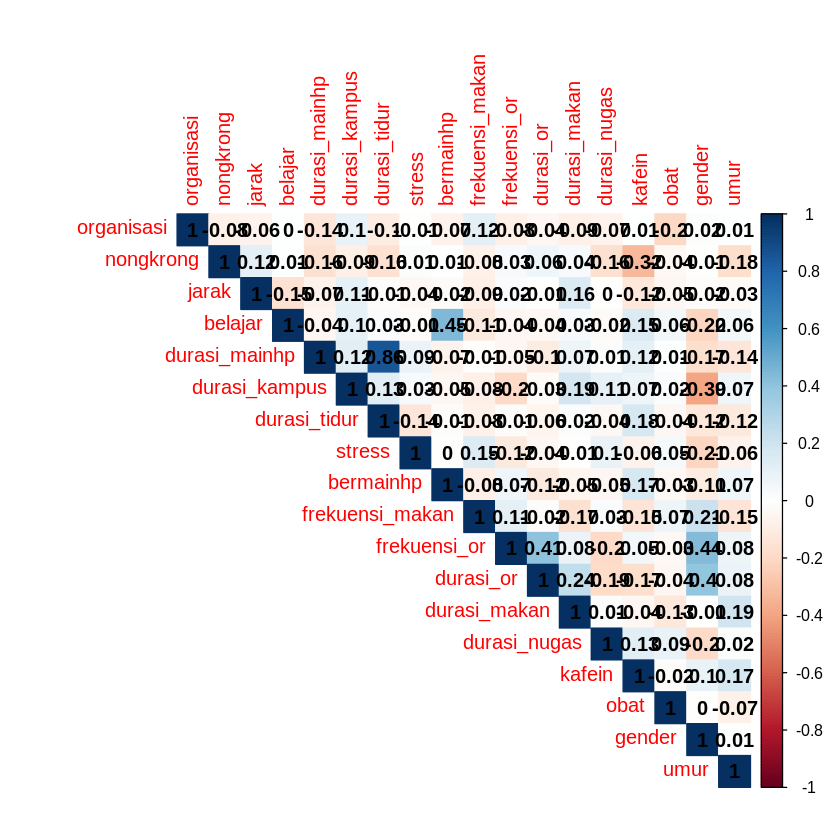

In [ ]:
# Install and load necessary packages
install.packages(c("corrplot", "dplyr"))
library(corrplot)
library(dplyr)

# Assuming df is your dataframe
numeric_df <- df %>%
  select_if(is.numeric)

# Create a correlation matrix
cor_matrix <- cor(numeric_df)

# Plot a correlation matrix heatmap
corrplot(cor_matrix, method = "color", type = "upper", addCoef.col = "black")

#### Korelasi Chi-Squared

In [ ]:
variabel <- c("organisasi", "bermainhp", "kafein", "obat", "gender")
jumlah_variabel <- length(variabel)

# Inisialisasi matriks untuk menyimpan nilai p-value
p_values <- matrix(NA, nrow = jumlah_variabel, ncol = jumlah_variabel, dimnames = list(variabel, variabel))

for (i in 1:(jumlah_variabel - 1)) {
  for (j in (i + 1):jumlah_variabel) {
    # Membuat tabel kontingensi
    tabel_kontingensi <- table(df[[variabel[i]]], df[[variabel[j]]])

    # Menjalankan uji chi-square
    hasil_chi_square <- chisq.test(tabel_kontingensi)

    # Menyimpan nilai p-value
    p_values[i, j] <- hasil_chi_square$p.value
    p_values[j, i] <- hasil_chi_square$p.value
  }
}

print(p_values)

Warning message in chisq.test(tabel_kontingensi):
“Chi-squared approximation may be incorrect”
Warning message in chisq.test(tabel_kontingensi):
“Chi-squared approximation may be incorrect”
Warning message in chisq.test(tabel_kontingensi):
“Chi-squared approximation may be incorrect”
Warning message in chisq.test(tabel_kontingensi):
“Chi-squared approximation may be incorrect”
Warning message in chisq.test(tabel_kontingensi):
“Chi-squared approximation may be incorrect”
Warning message in chisq.test(tabel_kontingensi):
“Chi-squared approximation may be incorrect”
Warning message in chisq.test(tabel_kontingensi):
“Chi-squared approximation may be incorrect”


           organisasi bermainhp    kafein      obat    gender
organisasi         NA 1.0000000 1.0000000 0.1402513 1.0000000
bermainhp   1.0000000        NA 0.6139852 1.0000000 0.9907753
kafein      1.0000000 0.6139852        NA 1.0000000 0.5134379
obat        0.1402513 1.0000000 1.0000000        NA 1.0000000
gender      1.0000000 0.9907753 0.5134379 1.0000000        NA


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



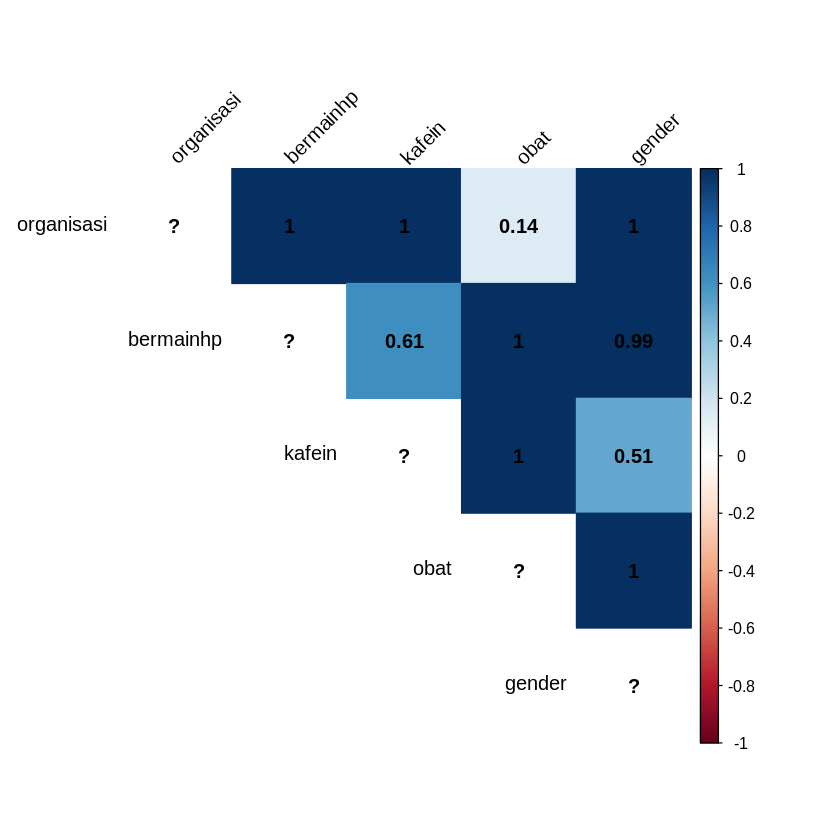

In [ ]:
install.packages("corrplot")
library(corrplot)

# Membuat heatmap untuk matriks p-value
corrplot(p_values, method = "color", type = "upper", addCoef.col = "black", tl.col = "black", tl.srt = 45)

## Data Prepocessing

#### Missing Value & Data Type

In [ ]:
missing_values <- sapply(df, function(x) sum(is.na(x)))
unique_values <- sapply(df, function(x) length(unique(x)))
data_types <- sapply(df, function(x) class(x))

summary_df <- data.frame(
  Missing_Values = missing_values,
  Unique_Values = unique_values,
  Data_Type = data_types)

summary_df

,Missing_Values,Unique_Values,Data_Type
,<int>,<int>,<chr>
organisasi,0,2,integer
nongkrong,0,14,numeric
jarak,0,50,numeric
belajar,0,17,numeric
durasi_mainhp,0,22,numeric
durasi_kampus,0,18,numeric
durasi_tidur,0,11,numeric
stress,0,10,numeric
bermainhp,0,2,integer


#### Outlier

In [ ]:
num_vars <- c('nongkrong', 'jarak', 'belajar','durasi_mainhp', 'durasi_kampus', 'durasi_tidur','frekuensi_makan',
              'frekuensi_or', 'durasi_or', 'durasi_makan', 'durasi_nugas', 'umur')

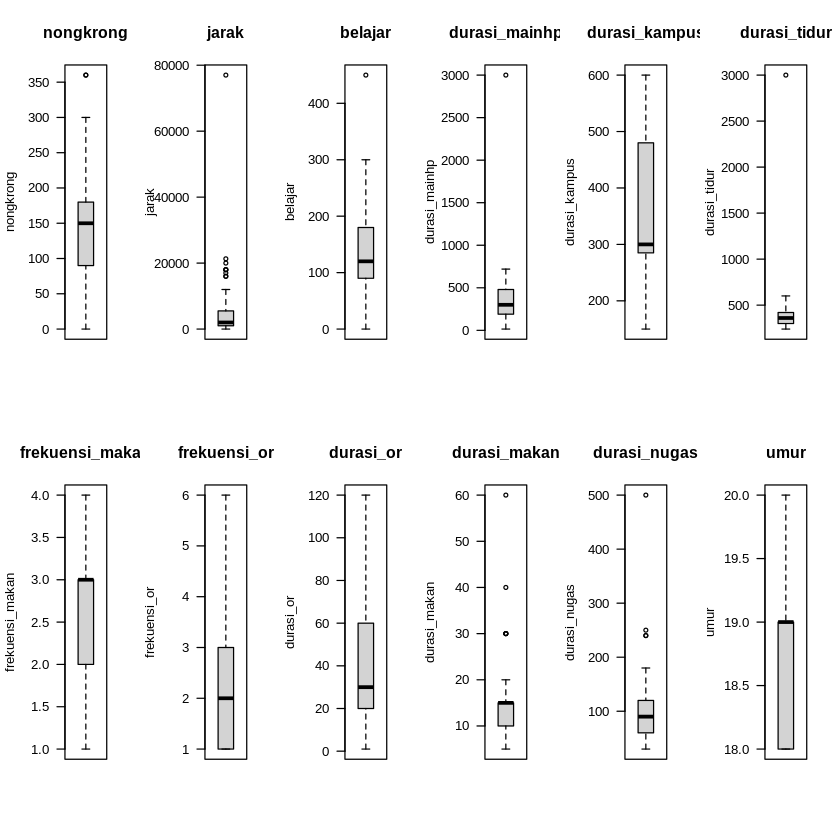

In [ ]:
# boxplot before
par(mfrow=c(2,6))
for (var in num_vars) {
  boxplot(df[[var]], main=var, ylab=var, las=2)}

In [ ]:
library(dplyr)
df2 <- df

replace_outliers_with_median <- function(data, vars) {
  for (var in vars) {
    Q1 <- quantile(data[[var]], 0.25)
    Q3 <- quantile(data[[var]], 0.75)
    IQR <- Q3 - Q1
    lower_bound <- Q1 - 1.5 * IQR
    upper_bound <- Q3 + 1.5 * IQR

    # Replace outliers with median
    data[[var]][data[[var]] < lower_bound] <- median(data[[var]], na.rm = TRUE)
    data[[var]][data[[var]] > upper_bound] <- median(data[[var]], na.rm = TRUE)
  }
  return(data)
}

df2_clean <- replace_outliers_with_median(df2, num_vars)
head(df2_clean)

organisasi,nongkrong,jarak,belajar,durasi_mainhp,durasi_kampus,durasi_tidur,stress,bermainhp,frekuensi_makan,frekuensi_or,durasi_or,durasi_makan,durasi_nugas,kafein,obat,gender,umur
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<dbl>
1,90,900,150,600,300,420,9,1,3,2,60,20,120,1,1,1,18
1,240,800,120,300,360,360,5,1,3,4,60,20,120,1,1,2,19
1,240,700,30,540,540,420,7,1,2,1,30,7,45,1,1,1,18
1,120,9000,120,480,300,420,9,1,3,2,60,20,120,1,1,1,19
1,120,2000,120,300,480,360,5,1,3,3,120,15,120,1,1,2,19
1,300,2000,0,480,150,480,5,1,3,4,1,10,100,1,1,2,18


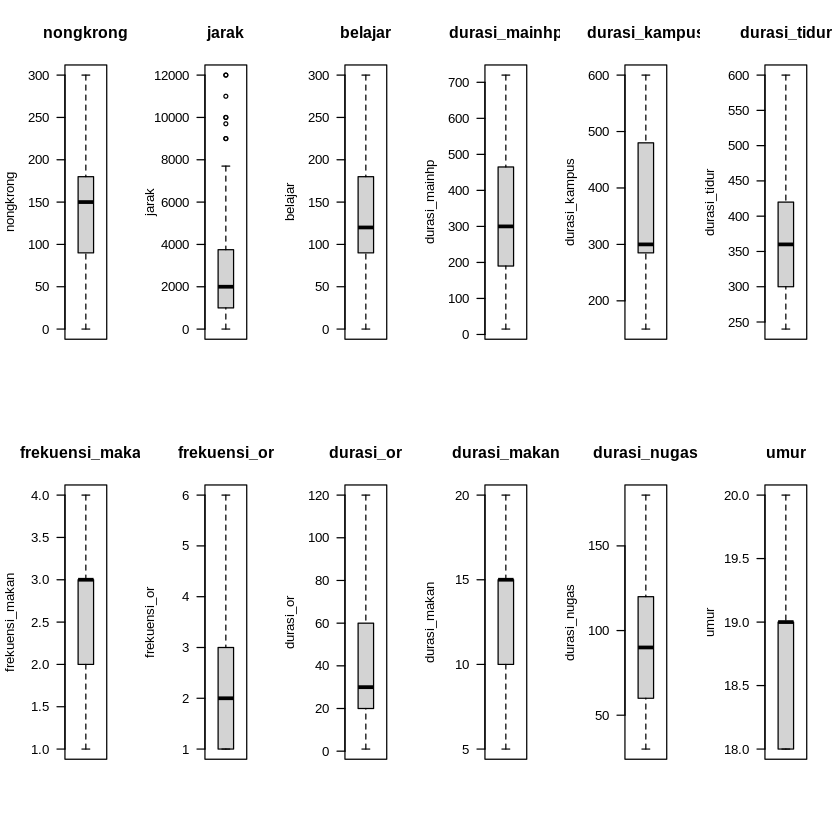

In [ ]:
# boxplot after
par(mfrow=c(2,6))
for (var in num_vars) {
  boxplot(df2_clean[[var]], main=var, ylab=var, las=2)}

#### Transformasi

##### Uji S-W

In [ ]:
shapiro_wilk_results <- function(data, vars) {
  results <- data.frame()

  for (var in vars) {
    test_result <- shapiro.test(data[[var]])
    decision <- ifelse(test_result$p.value < 0.05, "Tolak H0", "Terima H0")
    temp_df <- data.frame(Nama_Variable = var,
                          p_value = test_result$p.value,
                          Kepustakaan = decision)

    results <- rbind(results, temp_df)
  }
  return(results)
}

shapiro_results_df <- shapiro_wilk_results(df2_clean, num_vars)
shapiro_results_df


Nama_Variable,p_value,Kepustakaan
<chr>,<dbl>,<chr>
nongkrong,7.687489e-03,Tolak H0
jarak,5.489925e-10,Tolak H0
belajar,3.640805e-04,Tolak H0
durasi_mainhp,1.640543e-03,Tolak H0
durasi_kampus,2.378775e-03,Tolak H0
durasi_tidur,1.782656e-04,Tolak H0
frekuensi_makan,1.632380e-10,Tolak H0
frekuensi_or,1.004451e-09,Tolak H0
durasi_or,6.141546e-08,Tolak H0


##### Perform Transformasi

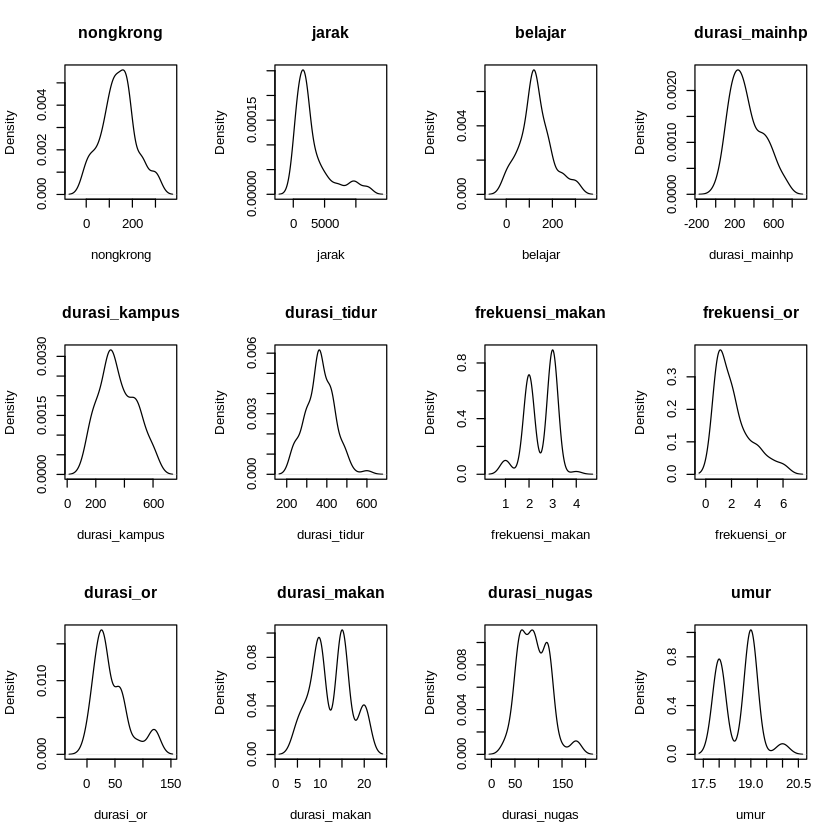

In [ ]:
par(mfrow=c(3, 4))

for (var in num_vars) {
  plot(density(df2_clean[[var]]), main=var, xlab=var, ylab="Density")
}

In [ ]:
df_normal <- df2_clean

# Transformasi SQRT
var_positiveskew<-c('jarak','durasi_mainhp', 'durasi_kampus')

for (var in var_positiveskew) {
  df_normal[[var]] <- sqrt(df_normal[[var]])
}

In [ ]:
var_multimodal <- c('frekuensi_makan', 'durasi_or', 'durasi_makan', 'durasi_nugas', 'umur')
for (var in var_multimodal) {
  df_normal[[var]] <- sqrt(df_normal[[var]])
}

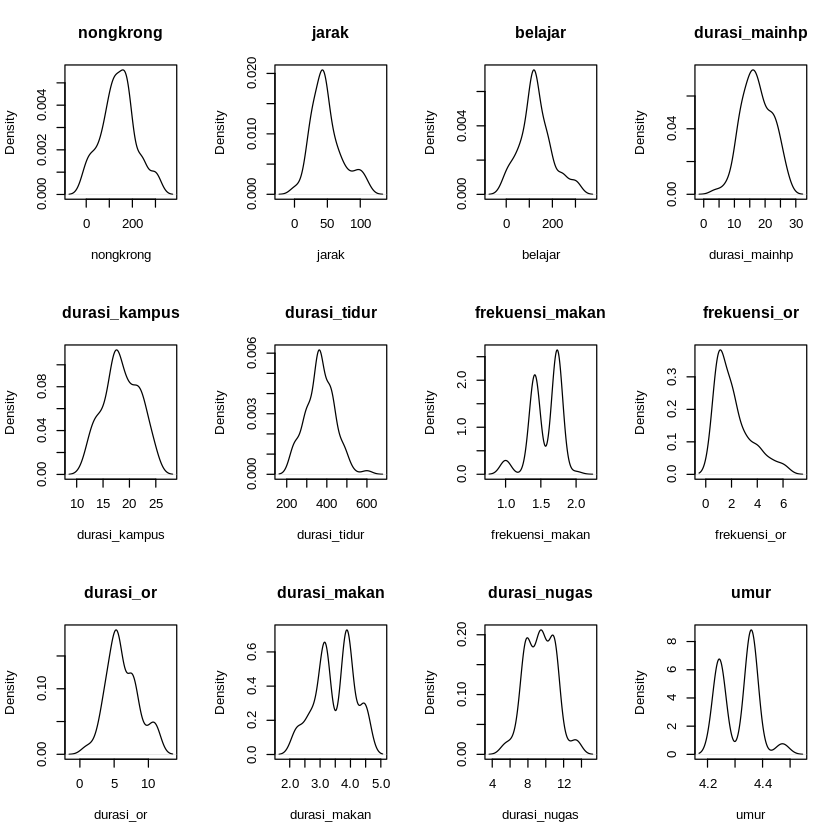

In [ ]:
par(mfrow=c(3, 4))

for (var in num_vars) {
  plot(density(df_normal[[var]]), main=var, xlab=var, ylab="Density")
}

#### Encoding


In [ ]:
cat_vars<-c('organisasi','bermainhp','kafein','obat','gender')

# Convert categorical variables to factors and then to integers
for (var in cat_vars) {
  df_normal[[var]] <- as.integer(factor(df_normal[[var]], levels = unique(df_normal[[var]])))
}

# Check the dataframe after encoding
head(df_normal)

organisasi,nongkrong,jarak,belajar,durasi_mainhp,durasi_kampus,durasi_tidur,stress,bermainhp,frekuensi_makan,frekuensi_or,durasi_or,durasi_makan,durasi_nugas,kafein,obat,gender,umur
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<dbl>
1,90,30.00000,150,24.49490,17.32051,420,9,1,1.732051,2,7.745967,4.472136,10.954451,1,1,1,4.242641
1,240,28.28427,120,17.32051,18.97367,360,5,1,1.732051,4,7.745967,4.472136,10.954451,1,1,2,4.358899
1,240,26.45751,30,23.23790,23.23790,420,7,1,1.414214,1,5.477226,2.645751,6.708204,1,1,1,4.242641
1,120,94.86833,120,21.90890,17.32051,420,9,1,1.732051,2,7.745967,4.472136,10.954451,1,1,1,4.358899
1,120,44.72136,120,17.32051,21.90890,360,5,1,1.732051,3,10.954451,3.872983,10.954451,1,1,2,4.358899
1,300,44.72136,0,21.90890,12.24745,480,5,1,1.732051,4,1.000000,3.162278,10.000000,1,1,2,4.242641


#### Normalisasi z-score


In [ ]:
# Normalisasi Z-Score untuk variabel numerik
scaled_vars <- scale(df_normal[, num_vars])

# Gabungkan hasil normalisasi dengan data asli
df_normal_scaled <- cbind(df_normal[, cat_vars, drop = FALSE], scaled_vars)

# Periksa hasil normalisasi
head(df_normal_scaled)

,organisasi,bermainhp,kafein,obat,gender,nongkrong,jarak,belajar,durasi_mainhp,durasi_kampus,durasi_tidur,frekuensi_makan,frekuensi_or,durasi_or,durasi_makan,durasi_nugas,umur
,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,1,1,1,1,-0.6743820,-0.7955852,0.3111209,1.465936074,-0.3495193,0.7451420,0.8049832,-0.1003904,0.6482700,1.5256123,0.9393883,-1.106866
2,1,1,1,1,2,1.3571704,-0.8672520,-0.1235823,-0.007152677,0.1459799,-0.1031985,0.8049832,1.3552698,0.6482700,1.5256123,0.9393883,0.647310
3,1,1,1,1,1,1.3571704,-0.9435565,-1.4276918,1.207841821,1.4240942,0.7451420,-0.6955290,-0.8282204,-0.3246516,-1.3205767,-1.6257140,-1.106866
4,1,1,1,1,1,-0.2680715,1.9139939,-0.1235823,0.934964008,-0.3495193,0.7451420,0.8049832,-0.1003904,0.6482700,1.5256123,0.9393883,0.647310
5,1,1,1,1,2,-0.2680715,-0.1806674,-0.1235823,-0.007152677,1.0257552,-0.1031985,0.8049832,0.6274397,2.0241889,0.5919089,0.9393883,0.647310
6,1,1,1,1,2,2.1697914,-0.1806674,-1.8623949,0.934964008,-1.8700620,1.5934825,0.8049832,1.3552698,-2.2446545,-0.5156358,0.3628169,-1.106866


#### Dimensional Reduction

#####Coba PCA

In [ ]:
# Melakukan PCA setelah normalisasi Z-Score
df_pca <-subset(df_normal_scaled, select = -durasi_tidur)
pca_result <- prcomp(df_pca, center = TRUE, scale. = TRUE)

# Melihat proporsi varians yang dijelaskan oleh setiap komponen utama
summary(pca_result)


# # Visualisasi hasil PCA
# fviz_pca_ind(pca_result, col.ind = df_normal_scaled$Response_Variable, palette = "jco", addEllipses = TRUE, pointsize = 2)
# fviz_pca_var(pca_result, col.var = "contrib", gradient.cols = c("#00AFBB", "#E7B800", "#FC4E07"), repel = TRUE)

Importance of components:
                          PC1    PC2    PC3     PC4     PC5     PC6     PC7
Standard deviation     1.4757 1.2929 1.2720 1.16336 1.11582 1.08386 1.03521
Proportion of Variance 0.1361 0.1045 0.1011 0.08459 0.07782 0.07342 0.06698
Cumulative Proportion  0.1361 0.2406 0.3417 0.42629 0.50410 0.57753 0.64451
                          PC8     PC9   PC10    PC11    PC12    PC13    PC14
Standard deviation     0.9642 0.92245 0.8872 0.81450 0.78718 0.75335 0.72837
Proportion of Variance 0.0581 0.05318 0.0492 0.04146 0.03873 0.03547 0.03316
Cumulative Proportion  0.7026 0.75579 0.8050 0.84645 0.88518 0.92065 0.95381
                          PC15    PC16
Standard deviation     0.67703 0.52985
Proportion of Variance 0.02865 0.01755
Cumulative Proportion  0.98245 1.00000

In [ ]:
print(pca_result$rotation)

                        PC1         PC2         PC3         PC4         PC5
organisasi       0.06597385 -0.16256257  0.11330197  0.62021409  0.05819374
bermainhp        0.03427857 -0.07175503  0.27000571 -0.38203293  0.37003625
kafein           0.07896829 -0.33906448  0.49238763 -0.13702348 -0.11585468
obat            -0.03783371  0.19816945  0.04492139 -0.24187998 -0.42851061
gender          -0.53610681 -0.20052718  0.01149061  0.09263844 -0.12046002
nongkrong       -0.08336697  0.23589178 -0.47968871 -0.27578721  0.24046267
jarak           -0.00124254  0.01816426 -0.08866419  0.16325195  0.56765831
belajar          0.25805632 -0.20787919 -0.16193481 -0.07924159 -0.38808331
durasi_mainhp    0.09574541  0.26743094 -0.15141781 -0.04883627 -0.27471433
durasi_kampus    0.39026496 -0.17028193 -0.08310291  0.15843216  0.03488532
frekuensi_makan -0.25138111  0.21664166  0.06885653  0.41290097 -0.18040078
frekuensi_or    -0.42251914 -0.31886136 -0.12815141 -0.14796712 -0.03678365
durasi_or   

#####Cek Eigen Values

In [ ]:
# Menampilkan eigenvalues
eigenvalues <- pca_result$sdev^2
print(eigenvalues)

 [1] 2.1775435 1.6716607 1.6179881 1.3534031 1.2450621 1.1747600 1.0716654
 [8] 0.9296474 0.8509196 0.7871295 0.6634046 0.6196490 0.5675298 0.5305205
[15] 0.4583751 0.2807416


## Analisis (Regresi Linear Berganda)

In [ ]:
# Membuat dataset baru dengan komponen utama hasil PCA
pca_data <- data.frame(PC1 = pca_result$x[, 1], PC2 = pca_result$x[, 2], PC3 = pca_result$x[, 3],
                       PC4 = pca_result$x[, 4], PC5 = pca_result$x[, 5], PC6 = pca_result$x[, 6], PC7 = pca_result$x[, 7])

# Menambahkan variabel response ke dataset PCA
pca_data$durasi_tidur <- df_normal_scaled$durasi_tidur

# Regresi Linear Berganda
reg_model <- lm(durasi_tidur ~ ., data = pca_data)

# Summary model
summary(reg_model)


Call:
lm(formula = durasi_tidur ~ ., data = pca_data)

Residuals:
    Min      1Q  Median      3Q     Max 
-2.0210 -0.7130 -0.0196  0.6054  3.1858 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)
(Intercept)  3.406e-16  1.094e-01   0.000    1.000
PC1          1.152e-02  7.454e-02   0.155    0.878
PC2          5.147e-02  8.507e-02   0.605    0.547
PC3         -6.535e-02  8.647e-02  -0.756    0.452
PC4         -6.541e-02  9.455e-02  -0.692    0.491
PC5          5.615e-02  9.857e-02   0.570    0.571
PC6         -1.041e-01  1.015e-01  -1.026    0.308
PC7         -9.751e-02  1.062e-01  -0.918    0.362

Residual standard error: 1.02 on 79 degrees of freedom
Multiple R-squared:  0.04426,	Adjusted R-squared:  -0.04042 
F-statistic: 0.5227 on 7 and 79 DF,  p-value: 0.8149


## Uji Asumsi Error

#### Uji Residual Normality

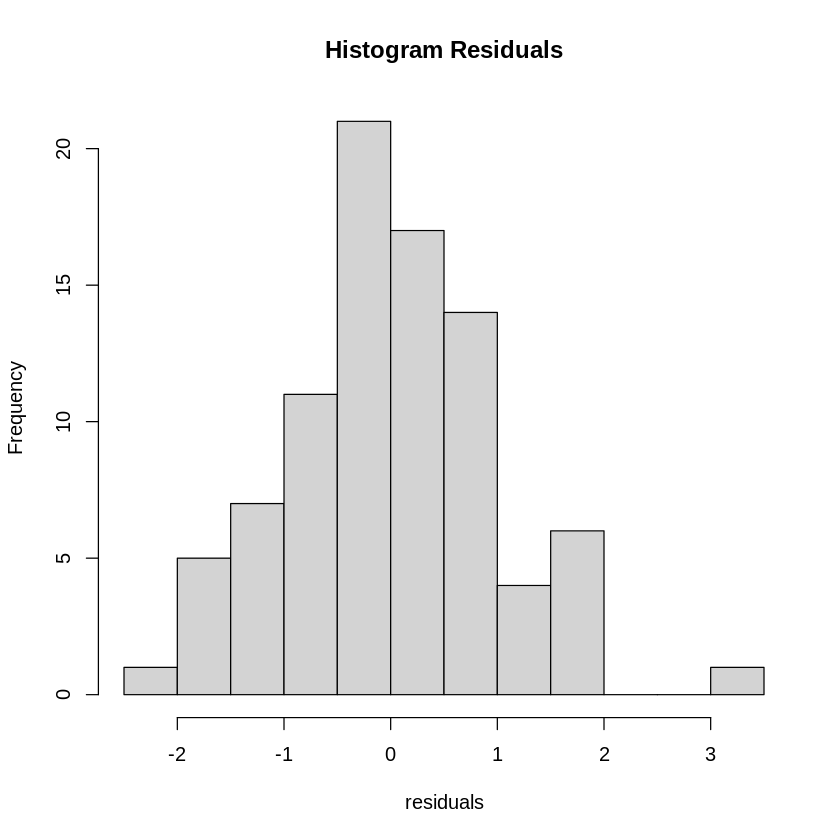


	Shapiro-Wilk normality test

data:  residuals
W = 0.98436, p-value = 0.3787


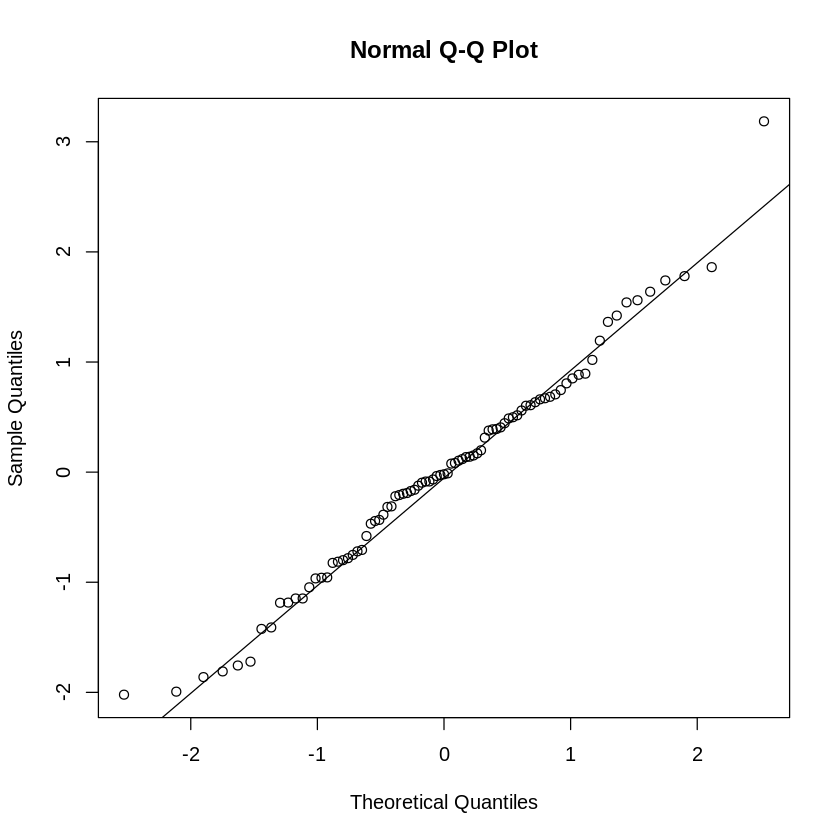

In [ ]:
# Melihat distribusi residual
residuals <- residuals(reg_model)
hist(residuals, main = "Histogram Residuals")

# Q-Q plot untuk mengecek normalitas residual
qqnorm(residuals)
qqline(residuals)

# Uji normalitas residual
shapiro.test(residuals)

#### Uji Autokorelasi

In [ ]:
# Install paket lmtest
install.packages("lmtest")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘zoo’




In [ ]:
# Memuat library lmtest
library(lmtest)

# Durbin Watson
dwtest(reg_model)

Loading required package: zoo


Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric





	Durbin-Watson test

data:  reg_model
DW = 2.3275, p-value = 0.9343
alternative hypothesis: true autocorrelation is greater than 0


#### Uji Heteroskedasitas

In [ ]:
# WHITE TEST
white_test_result <- bptest(reg_model)

# Menampilkan hasil uji White
print(white_test_result)

# Mengambil nilai p-value dari hasil uji White
p_value_white <- white_test_result$p.value

# Keputusan berdasarkan p-value
if (p_value_white < 0.05) {
  cat("H0 ditolak. Ada bukti kuat untuk heteroskedastisitas dalam residu.\n")
} else {
  cat("H0 tidak ditolak. Tidak ada bukti kuat untuk heteroskedastisitas dalam residu.\n")
}


	studentized Breusch-Pagan test

data:  reg_model
BP = 4.8159, df = 7, p-value = 0.6824

H0 tidak ditolak. Tidak ada bukti kuat untuk heteroskedastisitas dalam residu.


#### Uji Multikolineritas

In [ ]:
install.packages("car")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘numDeriv’, ‘SparseM’, ‘MatrixModels’, ‘minqa’, ‘nloptr’, ‘RcppEigen’, ‘carData’, ‘abind’, ‘pbkrtest’, ‘quantreg’, ‘lme4’




In [ ]:
# Install and load necessary packages

library(car)

# Menghitung VIF pada model regresi linear berganda
vif_values <- vif(reg_model)

# Menampilkan hasil
print(vif_values)

Loading required package: carData


Attaching package: ‘car’


The following object is masked from ‘package:dplyr’:

    recode




PC1 PC2 PC3 PC4 PC5 PC6 PC7 
  1   1   1   1   1   1   1 


In [ ]:
# Uji Linearitas pada model
print(anova(reg_model))

Analysis of Variance Table

Response: durasi_tidur
          Df Sum Sq Mean Sq F value Pr(>F)
PC1        1  0.025 0.02484  0.0239 0.8776
PC2        1  0.381 0.38091  0.3661 0.5469
PC3        1  0.594 0.59417  0.5711 0.4521
PC4        1  0.498 0.49805  0.4787 0.4910
PC5        1  0.338 0.33758  0.3245 0.5706
PC6        1  1.095 1.09469  1.0522 0.3081
PC7        1  0.876 0.87633  0.8423 0.3615
Residuals 79 82.193 1.04042               
